# 5.4 How much of O\*NET does Anthropic's AI evidence cover?

The app's AI-impact table shows, for each task of a career, Anthropic's **task coverage** (their labor-market impacts report). A task is *covered* when it had enough work-related Claude usage in August and November 2025 **and** is a task language models can do. Covered tasks are weighted 1.0 for automation-style use and 0.5 for augmentation-style use, so a value is either 0 or between 0.5 and 1 (`docs/DATA_SOURCES.md`).

So **0 means "not observed", not "safe from AI"**. This notebook measures how often that happens, and where.

Data: `data/duckdb/onet.duckdb` (O\*NET 31.0 tasks, Job Zones) and `data/duckdb/ai_impact.duckdb` (`task_coverage`, joined on the exact task text, CHANGELOG 027). No API calls.

In [1]:
import _setup
_setup.setup()

In [2]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

from career_rag.config import AI_IMPACT_DUCKDB_PATH, ONET_DUCKDB_PATH, RESEARCH_CLAIMS_PATH

# SOC 2018 major groups (BLS); the first two digits of an O*NET-SOC code.
SOC_MAJOR_GROUPS = {
    "11": "Management", "13": "Business and Financial Operations", "15": "Computer and Mathematical",
    "17": "Architecture and Engineering", "19": "Life, Physical, and Social Science",
    "21": "Community and Social Service", "23": "Legal", "25": "Educational Instruction and Library",
    "27": "Arts, Design, Entertainment, Sports, and Media", "29": "Healthcare Practitioners and Technical",
    "31": "Healthcare Support", "33": "Protective Service", "35": "Food Preparation and Serving Related",
    "37": "Building and Grounds Cleaning and Maintenance", "39": "Personal Care and Service",
    "41": "Sales and Related", "43": "Office and Administrative Support", "45": "Farming, Fishing, and Forestry",
    "47": "Construction and Extraction", "49": "Installation, Maintenance, and Repair", "51": "Production",
    "53": "Transportation and Material Moving", "55": "Military Specific",
}

con = duckdb.connect()
con.execute(f"ATTACH '{ONET_DUCKDB_PATH.as_posix()}' AS onet (READ_ONLY)")
con.execute(f"ATTACH '{AI_IMPACT_DUCKDB_PATH.as_posix()}' AS ai (READ_ONLY)")
tasks = con.execute("""
    SELECT t.onetsoc_code, t.task_id, t.task_type, z.job_zone, left(t.onetsoc_code, 2) AS soc_group, c.coverage
    FROM onet.task_statements AS t
    JOIN onet.job_zones AS z USING (onetsoc_code)
    LEFT JOIN ai.task_coverage AS c USING (onetsoc_code, task_id)
""").df()
tasks["group"] = tasks.soc_group.map(SOC_MAJOR_GROUPS)
tasks["zone"] = tasks.job_zone.map({2: "1-2", 3: "3", 4: "4", 5: "5"})  # O*NET 30.3+ merged Zones 1 and 2


def as_percent(table, columns):
    # The table with these share columns shown as percentages, renamed with a %.
    return table.assign(**{column: (table[column] * 100).round(1) for column in columns}).rename(
        columns={column: f"{column} %" for column in columns})


rated = tasks[tasks.coverage.notna()].assign(covered=lambda d: d.coverage > 0)
print(f"O*NET tasks: {len(tasks):,} in {tasks.onetsoc_code.nunique()} occupations")
print(f"with an Anthropic coverage value: {len(rated):,} ({len(rated) / len(tasks):.1%}); "
      f"the other {len(tasks) - len(rated)} are newer than Anthropic's task list")

O*NET tasks: 18,838 in 923 occupations
with an Anthropic coverage value: 18,681 (99.2%); the other 157 are newer than Anthropic's task list


## 1. Overall

In [3]:
occupations = (rated.groupby(["onetsoc_code", "group", "zone"]).covered.agg(["mean", "sum", "size"])
               .rename(columns={"mean": "share_covered", "sum": "covered_tasks", "size": "tasks"}).reset_index())
covered = rated[rated.covered]
print(f"tasks covered: {len(covered):,} of {len(rated):,} ({rated.covered.mean():.1%}); not covered (0): {(~rated.covered).mean():.1%}")
print(f"occupations with no covered task at all: {(occupations.covered_tasks == 0).sum()} of {len(occupations)} "
      f"({(occupations.covered_tasks == 0).mean():.0%})")
print(f"median share of an occupation's tasks covered: {occupations.share_covered.median():.1%}")
print(f"covered tasks' coverage value: median {covered.coverage.median():.2f} "
      f"(1.0 = automation-style, 0.5 = augmentation-style use)")

tasks covered: 1,721 of 18,681 (9.2%); not covered (0): 90.8%
occupations with no covered task at all: 442 of 923 (48%)
median share of an occupation's tasks covered: 3.6%
covered tasks' coverage value: median 0.90 (1.0 = automation-style, 0.5 = augmentation-style use)


## 2. By occupation group

Share of tasks covered, and share of occupations with at least one covered task. One colour, because there is one measure; the exact values are in the table.

In [4]:
by_group = (occupations.groupby("group")
            .agg(occupations=("onetsoc_code", "size"), with_any_covered=("covered_tasks", lambda s: (s > 0).mean()))
            .join(rated.groupby("group").agg(tasks=("covered", "size"), tasks_covered=("covered", "mean")))
            .sort_values("tasks_covered"))
as_percent(by_group, ["with_any_covered", "tasks_covered"])

,occupations,with_any_covered %,tasks,tasks_covered %
group,,,,
"Farming, Fishing, and Forestry",12,8.3,225,0.4
Construction and Extraction,61,11.5,1130,0.7
Transportation and Material Moving,52,11.5,908,0.9
Production,107,21.5,2129,1.2
"Installation, Maintenance, and Repair",50,14.0,1011,1.3
Food Preparation and Serving Related,16,25.0,320,1.6
Protective Service,26,30.8,510,2.2
Personal Care and Service,31,38.7,610,3.0
Building and Grounds Cleaning and Maintenance,8,37.5,162,3.1


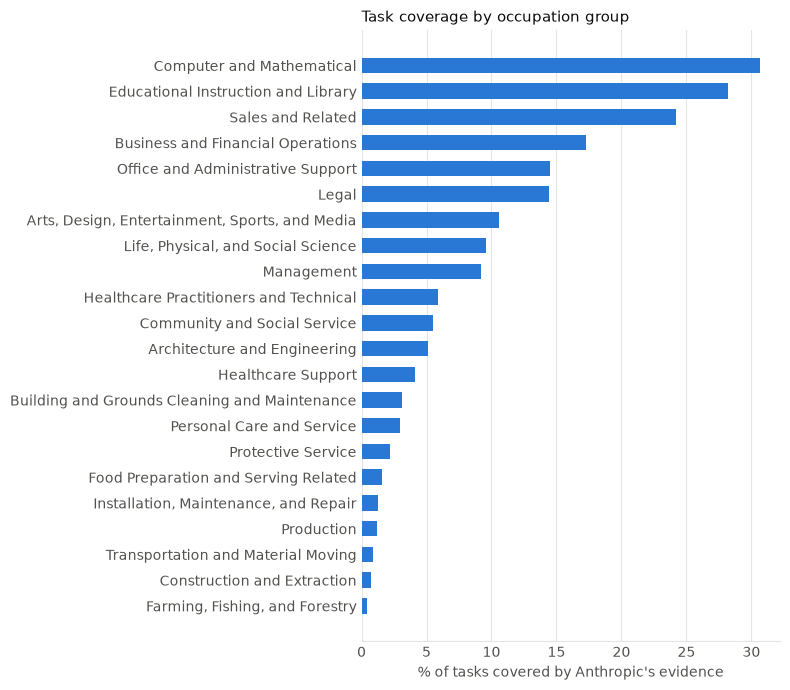

In [5]:
INK, MUTED, GRID, BAR = "#0b0b0b", "#52514e", "#e6e5e1", "#2a78d6"


def tidy(ax, title):
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.set_axisbelow(True)


fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(by_group.index, by_group.tasks_covered * 100, height=0.6, color=BAR)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_xlabel("% of tasks covered by Anthropic's evidence", color=MUTED)
tidy(ax, "Task coverage by occupation group")
plt.tight_layout()
plt.show()

## 3. By Job Zone (preparation needed)

,occupations,with_any_covered %,median_share %,tasks,tasks_covered %
zone,,,,,
1-2,337,27.3,0.0,6317,3.3
3,208,46.6,0.0,4192,5.9
4,226,74.3,10.0,4988,14.0
5,152,81.6,10.9,3184,17.8


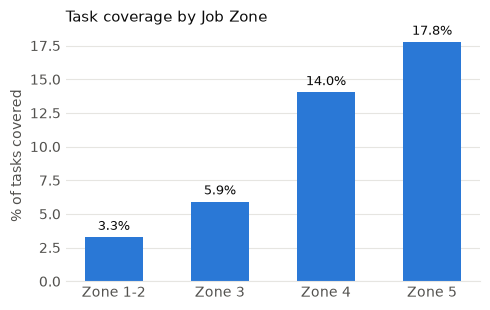

In [6]:
by_zone = (occupations.groupby("zone")
           .agg(occupations=("onetsoc_code", "size"), with_any_covered=("covered_tasks", lambda s: (s > 0).mean()),
                median_share=("share_covered", "median"))
           .join(rated.groupby("zone").agg(tasks=("covered", "size"), tasks_covered=("covered", "mean"))))
display(as_percent(by_zone, ["with_any_covered", "median_share", "tasks_covered"]))

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar("Zone " + by_zone.index, by_zone.tasks_covered * 100, width=0.55, color=BAR)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in by_zone.tasks_covered], padding=3, color=INK, fontsize=9)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_ylabel("% of tasks covered", color=MUTED)
tidy(ax, "Task coverage by Job Zone")
plt.tight_layout()
plt.show()

## 4. Are the differences real?

Tasks of the same occupation aren't independent observations, so the tests use **one value per occupation**: the share of its tasks that are covered.
- Job Zone is ordered, so Spearman's rank correlation.
- Occupation groups aren't ordered, so a Kruskal–Wallis test (no normality assumption; the shares are skewed, with many zeros).
- Core vs. supplemental tasks: compared **within** each occupation that has both, with a Wilcoxon signed-rank test.

In [7]:
zone_number = occupations.zone.map({"1-2": 2, "3": 3, "4": 4, "5": 5})
rho = stats.spearmanr(zone_number, occupations.share_covered)
print(f"Job Zone vs. share covered: Spearman rho = {rho.statistic:.2f}, p = {rho.pvalue:.1e}, n = {len(occupations)}")

groups = [g.share_covered for _, g in occupations.groupby("group")]
kw = stats.kruskal(*groups)
# Epsilon-squared effect size for Kruskal-Wallis: H / (n - 1)
print(f"occupation group: Kruskal-Wallis H = {kw.statistic:.0f}, p = {kw.pvalue:.1e}, "
      f"epsilon^2 = {kw.statistic / (len(occupations) - 1):.2f}")

by_type = (rated[rated.task_type.isin(["Core", "Supplemental"])]
           .pivot_table(index="onetsoc_code", columns="task_type", values="covered", aggfunc="mean").dropna())
difference = by_type.Core - by_type.Supplemental
wilcoxon = stats.wilcoxon(by_type.Core, by_type.Supplemental)
print(f"core vs. supplemental, {len(by_type)} occupations with both: core {by_type.Core.mean():.1%}, "
      f"supplemental {by_type.Supplemental.mean():.1%} covered on average; "
      f"Wilcoxon p = {wilcoxon.pvalue:.1e}; core higher in {(difference > 0).sum()}, lower in {(difference < 0).sum()}, "
      f"equal in {(difference == 0).sum()}")

Job Zone vs. share covered: Spearman rho = 0.48, p = 4.3e-54, n = 923
occupation group: Kruskal-Wallis H = 440, p = 4.4e-80, epsilon^2 = 0.48
core vs. supplemental, 765 occupations with both: core 10.0%, supplemental 6.5% covered on average; Wilcoxon p = 3.5e-14; core higher in 301, lower in 101, equal in 363


## 5. Careers with no AI evidence at all

A career shows "Not covered" on every task when none of its tasks is covered, and "no study in our collection is specific to this career yet" when it has no research claim (4.1c). Where both happen, the app has no AI evidence for that career.

In [8]:
with_claims = set(pd.read_csv(RESEARCH_CLAIMS_PATH, dtype=str).onetsoc_code)
occupations["has_claims"] = occupations.onetsoc_code.isin(with_claims)
occupations["no_evidence"] = (occupations.covered_tasks == 0) & ~occupations.has_claims
print(f"no covered task: {(occupations.covered_tasks == 0).sum()}; no research claim: {(~occupations.has_claims).sum()}; "
      f"neither: {occupations.no_evidence.sum()} of {len(occupations)}")
(occupations.groupby("group").no_evidence.agg(["sum", "size"]).rename(columns={"sum": "no_evidence", "size": "occupations"})
 .query("no_evidence > 0").sort_values("no_evidence", ascending=False))

no covered task: 442; no research claim: 207; neither: 142 of 923


,no_evidence,occupations
group,,
Construction and Extraction,23,61
Production,21,107
Transportation and Material Moving,20,52
"Installation, Maintenance, and Repair",20,50
Personal Care and Service,10,31
Protective Service,9,26
Architecture and Engineering,7,56
"Life, Physical, and Social Science",5,60
"Farming, Fishing, and Forestry",5,12


## Findings

The numbers above are recomputed on every run. What they show:

1. **Coverage is sparse.** About 9 in 10 task values are 0, and roughly half of all careers have no covered task, so their whole AI-impact table reads "Not covered". Covered tasks lean toward automation-style use (median value near 0.9).
2. **It follows preparation.** Coverage rises with every Job Zone step, and the occupation-level correlation is moderate and very unlikely to be chance. Careers that need more education are the ones where Claude use is observed.
3. **It follows the kind of work.** Computer and mathematical, education, sales, business and office work have the most coverage. Farming, construction, transportation, production and repair have almost none. Occupation group explains a large part of the variation.
4. **Core tasks are covered more often than supplemental ones** within the same occupation.

**What this means for the app:**
- "Not covered" is the most common thing a student sees, and it measures *where Claude is used*, not *what AI can or will do*. For manual and service careers that's mostly physical work outside a chat model's reach, but it is still absence of evidence, not evidence of safety. The table's caption says *covered* doesn't mean the job will disappear, but not the reverse: that *not covered* doesn't mean safe from AI. One added sentence would fix that (noted in ROADMAP 5.4).
- The careers without any AI evidence (section 5) are where Phase 8 should look for new sources first: research on robotics, physical automation and service work.

**Limits:** coverage reflects Claude usage only (one AI provider, users weighted toward the US) in two months of 2025, and 157 newer O\*NET tasks have no value.